In [1]:

from pathlib import Path
import sys
from ultralytics import YOLO

# 1. Project paths
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from bird_detection.evaluation.iou import calculate_iou
from bird_detection.evaluation.error_analysis import evaluate_image

# 2. Load trained model
model = YOLO(
    str(ROOT / "runs/train/yolo11n_baseline_v1/weights/best.pt")
)

DATASET = ROOT / "data/beach_bird/Beach Bird Detection Dataset v1.0"

# 3. Analyse two problematic images
for image_id in ["beach_bird_1419", "beach_bird_1498"]:

    image_path = DATASET / "images/val" / f"{image_id}.jpg"
    label_path = DATASET / "labels/val" / f"{image_id}.txt"

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        iou=0.7,
        device="mps",
        verbose=False
    )[0]

    analysis = evaluate_image(result, label_path)

    print(f"\n===== {image_id} =====")
    print("Ground Truth:", analysis["gt_count"])
    print("Predictions:", len(analysis["pred_boxes"]))

    for i, gt in enumerate(analysis["gt_boxes"]):
        overlaps = [
            calculate_iou(gt, pred)
            for pred in analysis["pred_boxes"]
        ]

        best_iou = max(overlaps, default=0.0)

        print(
            f"GT {i+1}: Best IoU = {best_iou:.3f}"
        )



===== beach_bird_1419 =====
Ground Truth: 5
Predictions: 3
GT 1: Best IoU = 0.000
GT 2: Best IoU = 0.383
GT 3: Best IoU = 0.202
GT 4: Best IoU = 0.443
GT 5: Best IoU = 0.000

===== beach_bird_1498 =====
Ground Truth: 4
Predictions: 6
GT 1: Best IoU = 0.252
GT 2: Best IoU = 0.192
GT 3: Best IoU = 0.224
GT 4: Best IoU = 0.449


In [2]:

import pandas as pd
import numpy as np

# Reuse the model, DATASET, and evaluate_image
# initialized in the previous analysis cell.

image_id = "beach_bird_1498"

image_path = DATASET / "images/val" / f"{image_id}.jpg"
label_path = DATASET / "labels/val" / f"{image_id}.txt"

result = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device="mps",
    verbose=False
)[0]

analysis = evaluate_image(result, label_path)


def box_area(box):
    x1, y1, x2, y2 = box
    return max(0, x2 - x1) * max(0, y2 - y1)


def box_center(box):
    x1, y1, x2, y2 = box
    return np.array([(x1 + x2) / 2, (y1 + y2) / 2])


rows = []

for i, gt in enumerate(analysis["gt_boxes"]):

    if not analysis["pred_boxes"]:
        continue

    ious = [
        calculate_iou(gt, pred)
        for pred in analysis["pred_boxes"]
    ]

    j = int(np.argmax(ious))
    pred = analysis["pred_boxes"][j]

    gt_area = box_area(gt)
    pred_area = box_area(pred)

    gt_diag = np.linalg.norm([
        gt[2] - gt[0],
        gt[3] - gt[1]
    ])

    center_distance = np.linalg.norm(
        box_center(gt) - box_center(pred)
    ) / max(gt_diag, 1e-9)

    rows.append({
        "GT": i + 1,
        "Best Pred": j + 1,
        "IoU": round(ious[j], 3),
        "Area Ratio": round(pred_area / gt_area, 3),
        "Center Distance": round(center_distance, 3)
    })

error_df = pd.DataFrame(rows)
display(error_df)


,GT,Best Pred,IoU,Area Ratio,Center Distance
0,1,2,0.252,0.252,0.037
1,2,4,0.192,0.192,0.030
2,3,3,0.224,0.224,0.044
3,4,1,0.449,0.449,0.024


In [3]:

# Check whether the best prediction is inside each GT box

for i, gt in enumerate(analysis["gt_boxes"]):
    j = int(error_df.iloc[i]["Best Pred"]) - 1
    pred = analysis["pred_boxes"][j]

    contained = (
        pred[0] >= gt[0] and
        pred[1] >= gt[1] and
        pred[2] <= gt[2] and
        pred[3] <= gt[3]
    )

    print(f"GT {i+1}: Prediction inside GT = {contained}")


GT 1: Prediction inside GT = True
GT 2: Prediction inside GT = True
GT 3: Prediction inside GT = True
GT 4: Prediction inside GT = True


In [4]:

from pathlib import Path
import sys
import numpy as np
import pandas as pd
from ultralytics import YOLO

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from bird_detection.evaluation.iou import calculate_iou
from bird_detection.evaluation.error_analysis import evaluate_image

DATASET = ROOT / "data/beach_bird/Beach Bird Detection Dataset v1.0"
model = YOLO(str(ROOT / "runs/train/yolo11n_baseline_v1/weights/best.pt"))

predictions = model.predict(
    source=str(DATASET / "images/val"),
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device="mps",
    stream=True,
    verbose=False,
)

audit_rows = []

for result in predictions:
    label_path = DATASET / "labels/val" / (
        Path(result.path).stem + ".txt"
    )
    a = evaluate_image(result, label_path)

    for i, gt in enumerate(a["gt_boxes"]):
        preds = a["pred_boxes"]

        if not preds:
            continue

        ious = [calculate_iou(gt, p) for p in preds]
        j = int(np.argmax(ious))
        best_iou = ious[j]

        if best_iou == 0:
            continue

        pred = preds[j]

        def area(b):
            return max(0, b[2]-b[0]) * max(0, b[3]-b[1])

        def center(b):
            return np.array([(b[0]+b[2])/2, (b[1]+b[3])/2])

        ratio = area(pred) / max(area(gt), 1e-9)
        diagonal = np.linalg.norm([gt[2]-gt[0], gt[3]-gt[1]])
        distance = np.linalg.norm(
            center(gt) - center(pred)
        ) / max(diagonal, 1e-9)

        contained = (
            pred[0] >= gt[0] and pred[1] >= gt[1]
            and pred[2] <= gt[2] and pred[3] <= gt[3]
        )

        audit_rows.append({
            "image": Path(result.path).name,
            "gt_index": i,
            "best_iou": best_iou,
            "area_ratio": ratio,
            "center_distance": distance,
            "contained": contained,
        })

audit_df = pd.DataFrame(audit_rows)

# Heuristic candidate rule, not a label-error diagnosis
candidates = audit_df[
    (audit_df["best_iou"] >= 0.1) &
    (audit_df["best_iou"] < 0.5) &
    (audit_df["contained"]) &
    (audit_df["center_distance"] < 0.1)
].copy()

print("Overlapping GT boxes:", len(audit_df))
print("Size-disagreement candidates:", len(candidates))
print("Affected images:", candidates["image"].nunique())

display(candidates.head(10))

output = ROOT / "runs/evaluation/yolo11n_failure_analysis"
output.mkdir(parents=True, exist_ok=True)
audit_df.to_csv(output / "box_audit.csv", index=False)


Overlapping GT boxes: 1788
Size-disagreement candidates: 17
Affected images: 10


,image,gt_index,best_iou,area_ratio,center_distance,contained
159,beach_bird_1388.jpg,3,0.465929,0.465929,0.024977,True
171,beach_bird_1388.jpg,15,0.415760,0.415760,0.047970,True
365,beach_bird_1419.jpg,1,0.383086,0.383086,0.036535,True
368,beach_bird_1420.jpg,0,0.381582,0.381582,0.078263,True
844,beach_bird_1497.jpg,1,0.461140,0.461140,0.040966,True
845,beach_bird_1497.jpg,2,0.446697,0.446697,0.056611,True
846,beach_bird_1497.jpg,3,0.302753,0.302753,0.030614,True
847,beach_bird_1498.jpg,0,0.251518,0.251518,0.037338,True
848,beach_bird_1498.jpg,1,0.192227,0.192227,0.030112,True
849,beach_bird_1498.jpg,2,0.224024,0.224024,0.044435,True


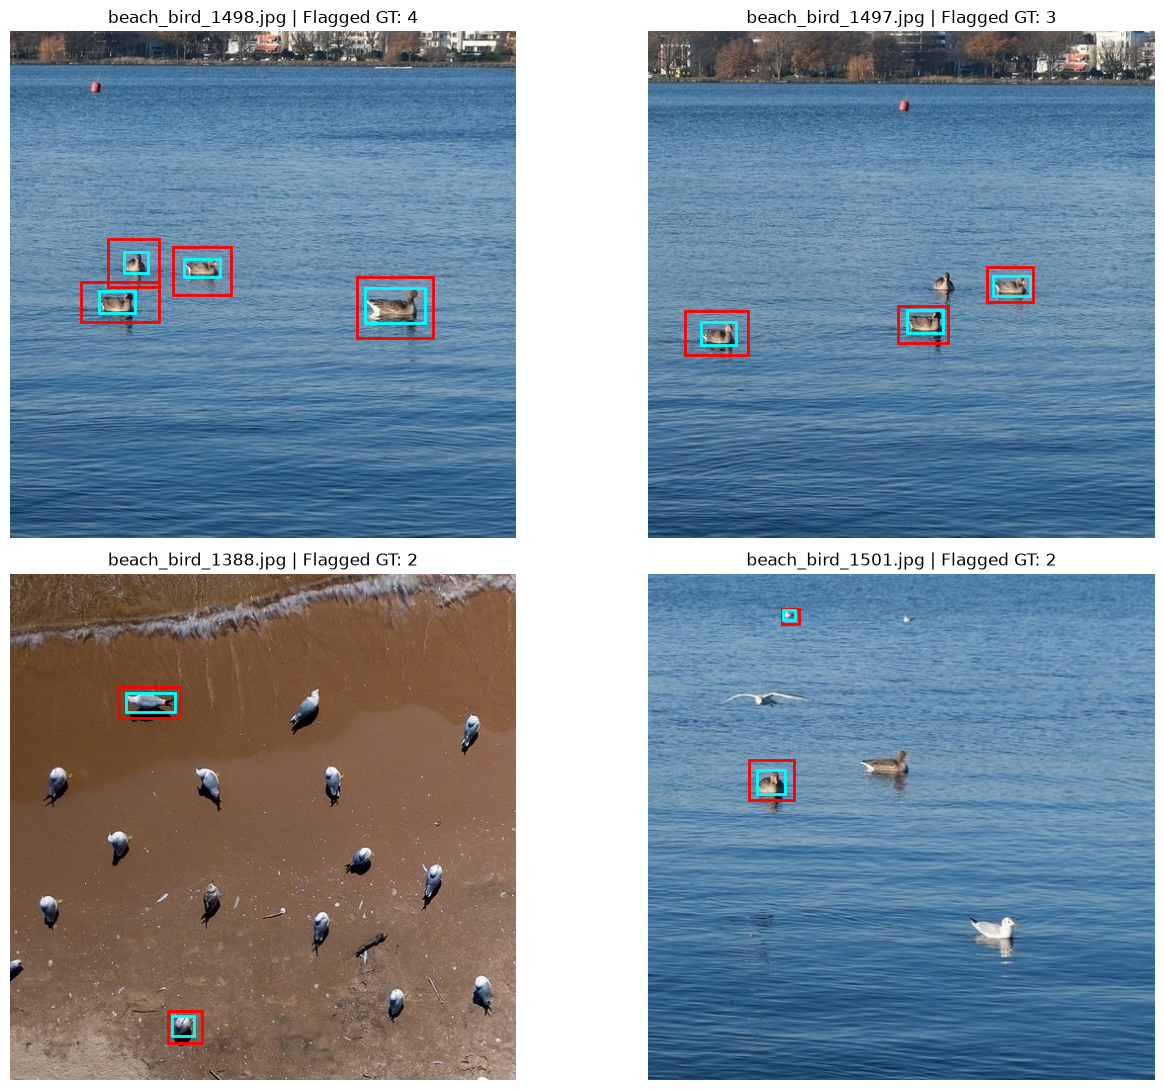

In [5]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
from bird_detection.evaluation.iou import calculate_iou

DATASET = ROOT / "data/beach_bird/Beach Bird Detection Dataset v1.0"

# Reload saved audit results
audit = pd.read_csv(
    ROOT / "runs/evaluation/yolo11n_failure_analysis/box_audit.csv"
)

candidates = audit[
    (audit.best_iou >= 0.1) &
    (audit.best_iou < 0.5) &
    (audit.contained) &
    (audit.center_distance < 0.1)
]

# Select four images with the most flagged boxes
top_images = candidates.image.value_counts().head(4).index

model = YOLO(
    str(ROOT / "runs/train/yolo11n_baseline_v1/weights/best.pt")
)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, filename in zip(axes.flat, top_images):
    image_path = DATASET / "images/val" / filename
    label_path = DATASET / "labels/val" / (
        Path(filename).stem + ".txt"
    )

    image = Image.open(image_path).convert("RGB")
    W, H = image.size

    result = model.predict(
        str(image_path),
        conf=0.25,
        iou=0.7,
        imgsz=640,
        device="mps",
        verbose=False
    )[0]

    preds = result.boxes.xyxy.cpu().tolist()
    labels = label_path.read_text().splitlines()

    ax.imshow(image)
    ax.axis("off")

    selected = candidates[candidates.image == filename]

    for gt_index in selected.gt_index:
        _, xc, yc, w, h = map(
            float, labels[int(gt_index)].split()
        )

        gt = [
            (xc - w/2) * W, (yc - h/2) * H,
            (xc + w/2) * W, (yc + h/2) * H
        ]

        if not preds:
            continue

        j = max(
            range(len(preds)),
            key=lambda j: calculate_iou(gt, preds[j])
        )
        pred = preds[j]

        # Red = Ground Truth
        # Cyan = Model Prediction
        for box, color in [(gt, "red"), (pred, "cyan")]:
            x1, y1, x2, y2 = box
            ax.add_patch(Rectangle(
                (x1, y1), x2-x1, y2-y1,
                fill=False, edgecolor=color, linewidth=2
            ))

    ax.set_title(
        f"{filename} | Flagged GT: {len(selected)}"
    )

plt.tight_layout()
plt.show()
